In [3]:
import os
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

## Tip 1: Entiende a la audiencia

In [4]:
#Carga de los datos
df = pd.read_csv("environment_data.csv")

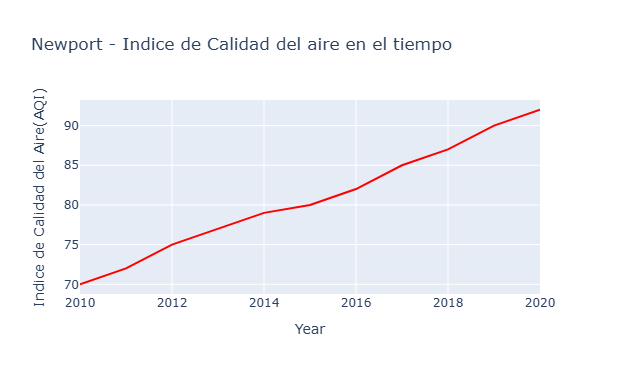

In [5]:
fig1= go.Figure()
fig1.add_trace(go.Scatter(x=df["Year"],y=df["AQI"],mode="lines",name="AQI",line=dict(color="red")))
fig1.update_layout(title="Newport - Indice de Calidad del aire en el tiempo",xaxis_title="Year",yaxis_title="Indice de Calidad del Aire(AQI)")
fig1.show()

## Tip 2: Usar la visualización correcta

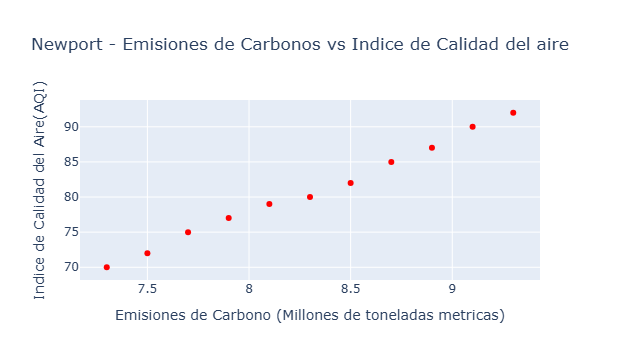

In [7]:
#Grafica de dispersión de emisiones de carbono vs AQI
fig2 = go.Figure()
fig2.add_trace(go.Scatter(x=df["Carbon_Emissions"],y=df["AQI"],mode="markers",name="Carbon Emissions vs AQI", marker=dict(color="red")))
fig2.update_layout(title="Newport - Emisiones de Carbonos vs Indice de Calidad del aire",xaxis_title="Emisiones de Carbono (Millones de toneladas metricas)",yaxis_title="Indice de Calidad del Aire(AQI)")
fig2.show()

## Tip 3: Enfatizar en los puntos clave

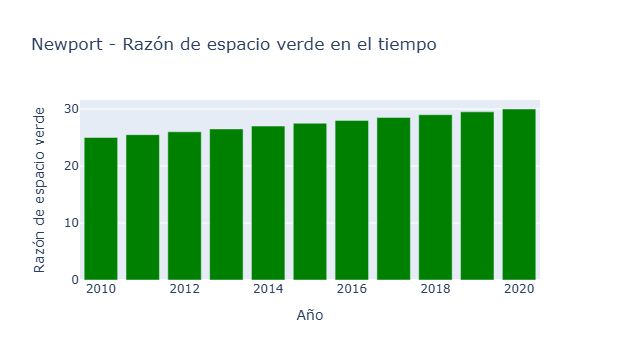

In [8]:
#Grafica de barras para razón de espacio verde en el tiempo
fig3 = go.Figure()
fig3.add_trace(go.Bar(x=df["Year"],y=df["Green_Space_Ratio"],name="Green Space Ratio", marker=dict(color="green")))
fig3.update_layout(title="Newport - Razón de espacio verde en el tiempo",xaxis_title="Año",yaxis_title="Razón de espacio verde")
fig3.show()

## Tip 4: Cuenta una historia con  tus datos

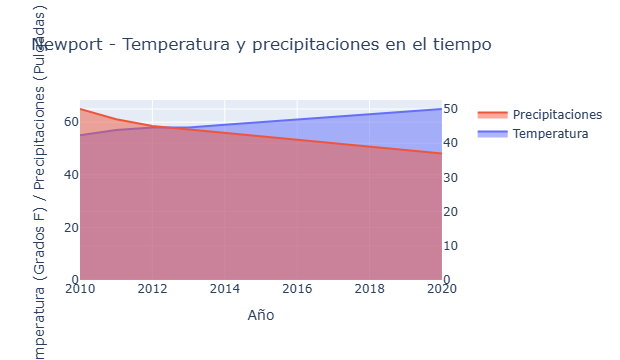

In [9]:
# Creación de gráfico de area apilada para Temperatura promedio y precipitaciones en el tiempo
fig4 = make_subplots(specs=[[{"secondary_y": True}]])
fig4.add_trace(go.Scatter(x=df['Year'], y=df['Temperature'], mode='lines', name='Temperatura',stackgroup='one'), secondary_y=False)
fig4.add_trace(go.Scatter(x=df['Year'], y=df['Rainfall'], mode='lines', name='Precipitaciones',stackgroup='one'), secondary_y=True)
fig4.update_layout(title='Newport - Temperatura y precipitaciones en el tiempo',xaxis_title='Año',yaxis_title='Temperatura (Grados F) / Precipitaciones (Pulgadas)')
fig4.show()

In [10]:
!pip install dash

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/8.9 MB ? eta -:--:--
   -------- ------------------------------- 1.8/8.9 MB 14.2 MB/s eta 0:00:01
   ---------------------- ----------------- 5.0/8.9 MB 14.6 MB/s eta 0:00:01
   --------------------------------- ------ 7.6/8.9 MB 13.5 MB/s eta 0:00:01
   ---------------------------------------- 8.9/8.9 MB 13.2 MB/s  0:00:00

   -------------------------- ------------- 2/3 [dash]
   -------------------------- ------------- 2/3 [dash]
   -------------------------- ------------- 2/3 [dash]
   -------------------------- ------------- 2/3 [dash]
   -------------------------- ------------- 2/3 [dash]
   -------------------------- ------------- 2/3 [dash]
   -------------------------- ------------- 2/3 [dash]
   ---------------------------------------- 3/3 [dash]



  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [12]:
import dash
from dash import dcc
from dash import html

# Consolidación de gráficos

app = dash.Dash(__name__)
app.layout = html.Div([
    html.H1('Cuadro de Control de Mando (Dashboard)'),
    
    html.Div([
        dcc.Graph(figure=fig1),
        dcc.Graph(figure=fig2),
    ], style={'display': 'flex'}),
    
    html.Div([
        dcc.Graph(figure=fig3),
        dcc.Graph(figure=fig4),
    ], style={'display': 'flex'}),
])

if __name__ == '__main__':
    app.run(debug=True)